In [3]:
import pandas as pd

df = pd.read_excel(
    r"C:\Users\chigi\OneDrive\Documents\pd_speech_features.csv.xlsx",
    header=1,
    engine="openpyxl"
)

print("Shape:", df.shape)
print(df.columns.tolist())

Shape: (756, 755)
['id', 'gender', 'PPE', 'DFA', 'RPDE', 'numPulses', 'numPeriodsPulses', 'meanPeriodPulses', 'stdDevPeriodPulses', 'locPctJitter', 'locAbsJitter', 'rapJitter', 'ppq5Jitter', 'ddpJitter', 'locShimmer', 'locDbShimmer', 'apq3Shimmer', 'apq5Shimmer', 'apq11Shimmer', 'ddaShimmer', 'meanAutoCorrHarmonicity', 'meanNoiseToHarmHarmonicity', 'meanHarmToNoiseHarmonicity', 'minIntensity', 'maxIntensity', 'meanIntensity', 'f1', 'f2', 'f3', 'f4', 'b1', 'b2', 'b3', 'b4', 'GQ_prc5_95', 'GQ_std_cycle_open', 'GQ_std_cycle_closed', 'GNE_mean', 'GNE_std', 'GNE_SNR_TKEO', 'GNE_SNR_SEO', 'GNE_NSR_TKEO', 'GNE_NSR_SEO', 'VFER_mean', 'VFER_std', 'VFER_entropy', 'VFER_SNR_TKEO', 'VFER_SNR_SEO', 'VFER_NSR_TKEO', 'VFER_NSR_SEO', 'IMF_SNR_SEO', 'IMF_SNR_TKEO', 'IMF_SNR_entropy', 'IMF_NSR_SEO', 'IMF_NSR_TKEO', 'IMF_NSR_entropy', 'mean_Log_energy', 'mean_MFCC_0th_coef', 'mean_MFCC_1st_coef', 'mean_MFCC_2nd_coef', 'mean_MFCC_3rd_coef', 'mean_MFCC_4th_coef', 'mean_MFCC_5th_coef', 'mean_MFCC_6th_coef',

In [4]:
from math import log2
def entropy(data):
    counts=data.value_counts()
    probabilities=counts/len(data)
    result=0

    for p in probabilities:
        result -= p*log2(p)

    return result
entropy_class = entropy(df["class"])
print(entropy_class)

0.8175072881213616


In [5]:
def gini(data):
    probabilities=data.value_counts(normalize=True)
    result=1

    for p in probabilities:
        result -=p**2

    return result
gini_class=gini(df["class"])
print(gini_class)


0.3789367598891409


In [6]:
import numpy as np

def information_gain(parent, left, right):
    total = len(parent)
    return entropy(parent) - ((len(left) / total) * entropy(left) + (len(right) / total) * entropy(right))

def best_split(data, target, feature):
    values = data[feature].dropna()

    if values.nunique() < 2:
        return -1, None

    thresholds = np.percentile(values, [25, 50, 75])
    best_gain = -1
    best_value = None

    for value in thresholds:
        left = data[feature] <= value
        right = data[feature] > value

        if left.sum() == 0 or right.sum() == 0:
            continue

        gain = information_gain(target, target[left], target[right])

        if gain > best_gain:
            best_gain = gain
            best_value = value

    return best_gain, best_value

def find_root(data, target):
    features = data.select_dtypes(include=np.number).columns
    features = features.drop([target, "id"], errors="ignore")

    result = []

    for feature in features:
        gain, value = best_split(data, data[target], feature)
        result.append((feature, gain, value))

    return max(result, key=lambda x: x[1])

root, gain, split = find_root(df, "class")

print("Root Feature:", root)
print("Information Gain:", gain)
print("Split Value:", split)

Root Feature: tqwt_entropy_shannon_dec_12
Information Gain: 0.10967153754363412
Split Value: 100.6455


In [13]:
def binning(data, feature, method="equal_width", bins=4):
    if method == "equal_width":
        return pd.cut(data[feature], bins=bins)
    elif method == "equal_frequency":
        return pd.qcut(data[feature], q=bins, duplicates="drop")
df["root_binned"] = binning(df, "tqwt_entropy_shannon_dec_12")

print(df["root_binned"].value_counts())

root_binned
(-2.615, 655.804]       735
(655.804, 1311.6]        17
(1311.6, 1967.396]        3
(1967.396, 2623.192]      1
Name: count, dtype: int64


In [17]:
def information_gain(parent, left, right):
    total = len(parent)
    weighted = (len(left) / total) * entropy(left) + (len(right) / total) * entropy(right)
    return entropy(parent) - weighted

def best_feature(data, target, features):
    best = None
    best_gain = -1
    best_value = None

    for feature in features:
        values = data[feature].dropna().unique()

        for value in values:
            left = data[feature] == value
            right = data[feature] != value

            if left.sum() == 0 or right.sum() == 0:
                continue

            gain = information_gain(target, target[left], target[right])

            if gain > best_gain:
                best = feature
                best_gain = gain
                best_value = value

    return best, best_gain, best_value

def decision_tree(data, target, features, depth=0, max_depth=3):
    if len(target.unique()) == 1:
        return target.iloc[0]

    if depth == max_depth or len(features) == 0:
        return target.mode()[0]

    feature, gain, value = best_feature(data, target, features)

    if feature is None:
        return target.mode()[0]

    left = data[feature] == value
    right = data[feature] != value

    remaining = [f for f in features if f != feature]

    return {
        feature: {
            str(value): decision_tree(data[left], target[left], remaining, depth + 1, max_depth),
            "other": decision_tree(data[right], target[right], remaining, depth + 1, max_depth)
        }
    }

In [19]:
features = ["root_binned"]

tree = decision_tree(df, df["class"], features)

print(tree)

{'root_binned': {'(-2.615, 655.804]': 1, 'other': 0}}


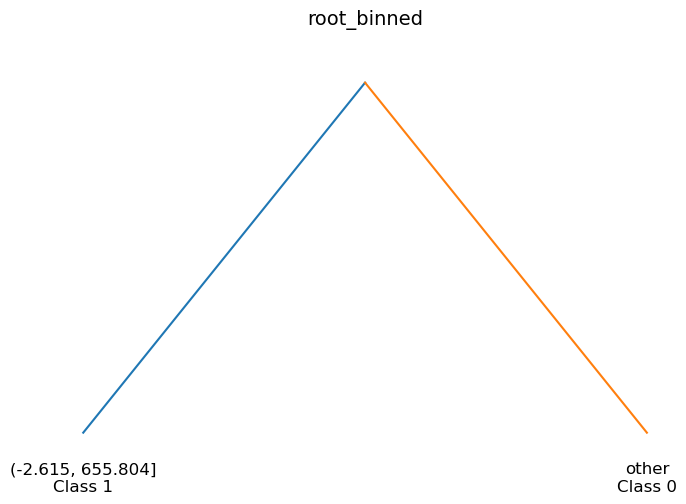

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.text(0.5, 0.8, "root_binned", ha="center", fontsize=14)

plt.text(0.25, 0.4, "(-2.615, 655.804]\nClass 1", ha="center", fontsize=12)
plt.text(0.75, 0.4, "other\nClass 0", ha="center", fontsize=12)

plt.plot([0.5, 0.25], [0.75, 0.45])
plt.plot([0.5, 0.75], [0.75, 0.45])

plt.axis("off")
plt.show()

C:\Users\chigi\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


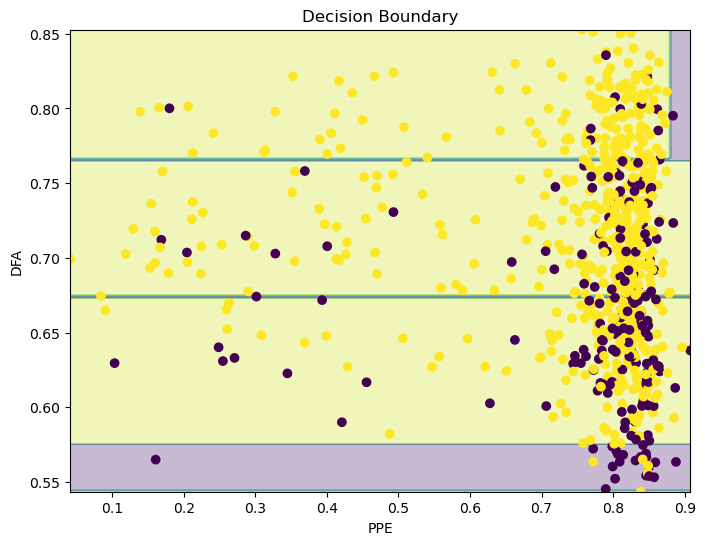

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
def decision_boundary(data, target, feature1, feature2):
    x = data[[feature1, feature2]].dropna()
    y = target[x.index]

    model = DecisionTreeClassifier(max_depth=3, random_state=42)
    model.fit(x, y)

    x1 = np.linspace(x[feature1].min(), x[feature1].max(), 200)
    x2 = np.linspace(x[feature2].min(), x[feature2].max(), 200)

    xx, yy = np.meshgrid(x1, x2)

    points = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(points)
    predictions = predictions.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, predictions, alpha=0.3)
    plt.scatter(x[feature1], x[feature2], c=y)
    plt.xlabel(feature1)
    plt.ylabel(feature2)
    plt.title("Decision Boundary")
    plt.show()

    return model
model = decision_boundary(df, df["class"], "PPE", "DFA")

In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
def tune_tree(X, y):
    model = DecisionTreeClassifier(random_state=42)

    parameters = {
        "max_depth": [2, 3, 4, 5, 6],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    }

    search = GridSearchCV(model, parameters, cv=5)
    search.fit(X, y)

    return search
X = df[["PPE", "DFA"]]
y = df["class"]

search = tune_tree(X, y)

print("Best Parameters:", search.best_params_)
print("Best Score:", search.best_score_)

Best Parameters: {'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best Score: 0.7566573719065877
